In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("../data/raw/Case_Study_2_CLV_Predictive_Analytics.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

Dataset shape: (2000, 9)


In [2]:
print("Exact duplicate rows:", df.duplicated().sum())

print("Duplicate array IDs:", df["array_id"].duplicated().sum())

print("Missing account IDs:", df["account_id"].isna().sum())

print("Missing array IDs:", df["array_id"].isna().sum())

print("Unique accounts:", df["account_id"].nunique())

print("Unique arrays:", df["array_id"].nunique())

Exact duplicate rows: 0
Duplicate array IDs: 0
Missing account IDs: 0
Missing array IDs: 0
Unique accounts: 1000
Unique arrays: 2000


In [3]:
missing_audit = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
})

display(missing_audit)

,missing_count,missing_percentage
account_id,0,0.0
array_id,0,0.0
contract_end_date,0,0.0
historical_15yr_net_profit_usd,0,0.0
current_capacity_tb,0,0.0
utilization_rate_pct,0,0.0
static_baseline_churn_rate,0,0.0
churn_event_next_12m,116,5.8
expansion_potential_signal,0,0.0


In [4]:
account_label_counts = (
    df.groupby("account_id")["churn_event_next_12m"]
    .nunique(dropna=True)
)

mixed_accounts = account_label_counts[
    account_label_counts > 1
].index

print("Accounts with mixed churn labels:", len(mixed_accounts))

display(
    df[df["account_id"].isin(mixed_accounts)]
    .sort_values(["account_id", "array_id"])
    .head(10)
)

Accounts with mixed churn labels: 224


,account_id,array_id,contract_end_date,historical_15yr_net_profit_usd,current_capacity_tb,utilization_rate_pct,static_baseline_churn_rate,churn_event_next_12m,expansion_potential_signal
0,ACC_1000,ARR_5000,2026-10-01,146797,1382,0.59,0.05,0.0,Medium
1000,ACC_1000,ARR_6000,2028-02-13,1961369,584,0.74,0.05,1.0,Low
1,ACC_1001,ARR_5001,2026-10-01,1236408,1809,0.93,0.05,1.0,UNKNOWN
1001,ACC_1001,ARR_6001,2028-02-13,264758,1134,0.40,0.05,0.0,UNKNOWN
2,ACC_1002,ARR_5002,2026-10-02,2790632,605,1.28,0.05,0.0,Low
1002,ACC_1002,ARR_6002,2028-02-14,3091683,1429,1.44,0.05,1.0,Low
18,ACC_1018,ARR_5018,2026-10-10,1054272,1909,0.54,0.05,0.0,Medium
1018,ACC_1018,ARR_6018,2028-02-22,1616126,2270,0.73,0.05,1.0,Medium
20,ACC_1020,ARR_5020,2026-10-11,2083721,1015,1.23,0.05,1.0,Low
1020,ACC_1020,ARR_6020,2028-02-23,128552,1085,0.54,0.05,0.0,Medium


In [5]:
print("Unique non-missing churn labels:")
print(df["churn_event_next_12m"].dropna().unique())

print("\nChurn label counts:")
print(df["churn_event_next_12m"].value_counts(dropna=False))

print("\nObserved churn rate among labeled records:")
print(
    round(
        df["churn_event_next_12m"].dropna().mean() * 100,
        2
    ),
    "%"
)

Unique non-missing churn labels:
[0. 1.]

Churn label counts:
churn_event_next_12m
0.0    1586
1.0     298
NaN     116
Name: count, dtype: int64

Observed churn rate among labeled records:
15.82 %


## 2.2 — Storage Utilization Investigation

Objective: Examine utilization values and determine
an appropriate preprocessing strategy.

In [6]:
util = df["utilization_rate_pct"]

print("Utilization Statistics")
print(util.describe())

print("\nMinimum:", util.min())
print("Maximum:", util.max())

print("\nValues below 0:", (util < 0).sum())
print("Values between 0 and 1:", util.between(0, 1).sum())
print("Values above 1:", (util > 1).sum())

print("\nPercentage above 1:",
      round((util > 1).mean() * 100, 2), "%")

Utilization Statistics
count    2000.000000
mean        0.917040
std         0.312321
min         0.350000
25%         0.660000
50%         0.930000
75%         1.180000
max         1.450000
Name: utilization_rate_pct, dtype: float64

Minimum: 0.35
Maximum: 1.45

Values below 0: 0
Values between 0 and 1: 1138
Values above 1: 862

Percentage above 1: 43.1 %


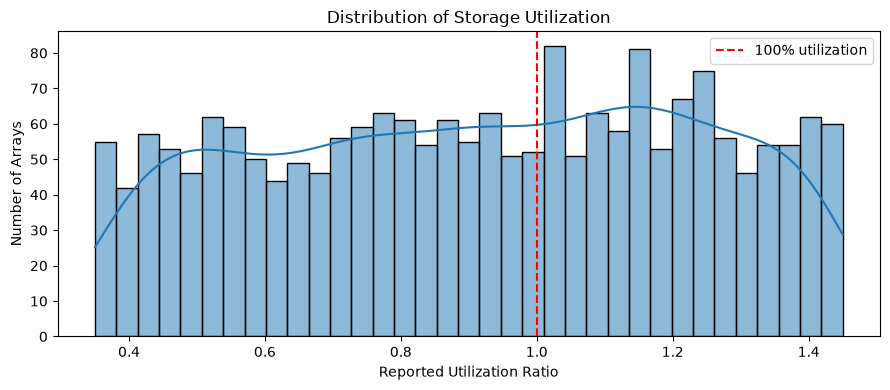

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 4))

sns.histplot(df["utilization_rate_pct"],
             bins=35,
             kde=True)

plt.axvline(
    x=1.0,
    color="red",
    linestyle="--",
    label="100% utilization"
)

plt.title("Distribution of Storage Utilization")
plt.xlabel("Reported Utilization Ratio")
plt.ylabel("Number of Arrays")
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
util_analysis = df.copy()

util_analysis["util_group"] = pd.cut(
    util_analysis["utilization_rate_pct"],
    bins=[-float("inf"), 0.5, 0.8, 1.0, float("inf")],
    labels=["<=50%", "50-80%", "80-100%", ">100%"]
)

util_summary = (
    util_analysis.groupby("util_group", observed=True)
    .agg(
        total_arrays=("array_id", "count"),
        labeled_arrays=("churn_event_next_12m", "count"),
        churn_events=("churn_event_next_12m", "sum"),
        observed_churn_rate=("churn_event_next_12m", "mean")
    )
)

util_summary["observed_churn_rate"] *= 100

display(util_summary.round(2))

,total_arrays,labeled_arrays,churn_events,observed_churn_rate
util_group,,,,
<=50%,253,238,38.0,15.97
50-80%,518,485,86.0,17.73
80-100%,367,349,58.0,16.62
>100%,862,812,116.0,14.29


In [9]:
util_analysis["utilization_above_100_flag"] = (
    util_analysis["utilization_rate_pct"] > 1.0
).astype(int)

print(
    util_analysis["utilization_above_100_flag"]
    .value_counts()
)

utilization_above_100_flag
0    1138
1     862
Name: count, dtype: int64


### Utilization Analysis — Findings

- Utilization ranges from 0.35 to 1.45, with a mean of 0.917.
- 862 arrays (43.1%) have reported utilization above 1.0.
- No negative utilization values were found.
- Arrays above 100% utilization have an observed churn rate
  of 14.29%, compared with 17.73% for the 50–80% group.
- These differences are descriptive associations, not
  evidence of causation.
- Values above 100% may reflect overprovisioning, a metric
  definition issue, or data-quality problems.

Preprocessing decision:
Preserve the original utilization values and create a
binary indicator for values above 1.0. Evaluate whether
the indicator improves model performance during validation.

## 2.3–2.8 — Profit, Capacity, Data Quality and Preprocessing

Objective:
- Investigate profit and capacity distributions
- Identify potentially invalid observations
- Examine feature relationships with churn
- Establish leakage-safe model features
- Prepare account-grouped training, validation and testing data

In [10]:
# Profit and capacity summary
cols = [
    "historical_15yr_net_profit_usd",
    "current_capacity_tb"
]

display(df[cols].describe())

print("Negative profit records:",
      (df["historical_15yr_net_profit_usd"] < 0).sum())

print("Zero/negative capacity records:",
      (df["current_capacity_tb"] <= 0).sum())

,historical_15yr_net_profit_usd,current_capacity_tb
count,2.000000e+03,2000.000000
mean,2.152845e+06,1282.771000
std,1.330932e+06,699.754635
min,-9.378000e+04,53.000000
25%,9.966938e+05,673.500000
50%,2.134328e+06,1305.500000
75%,3.277240e+06,1880.000000
max,4.498824e+06,2498.000000


Negative profit records: 58
Zero/negative capacity records: 0


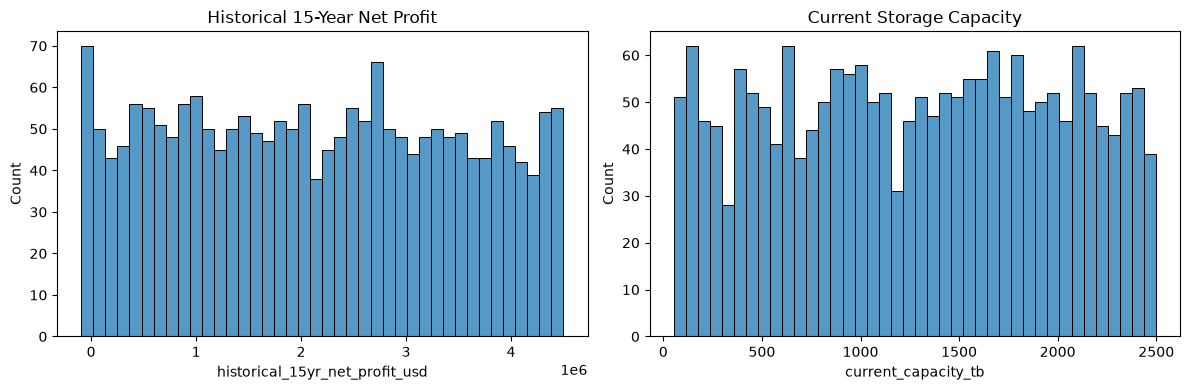

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    df["historical_15yr_net_profit_usd"],
    bins=40,
    ax=axes[0]
)
axes[0].set_title("Historical 15-Year Net Profit")

sns.histplot(
    df["current_capacity_tb"],
    bins=40,
    ax=axes[1]
)
axes[1].set_title("Current Storage Capacity")

plt.tight_layout()
plt.show()

In [12]:
expansion_summary = (
    df.groupby("expansion_potential_signal")
      .agg(
          total_arrays=("array_id", "count"),
          labeled_arrays=("churn_event_next_12m", "count"),
          churn_rate=("churn_event_next_12m", "mean")
      )
)

expansion_summary["churn_rate"] *= 100

display(expansion_summary.round(2))

,total_arrays,labeled_arrays,churn_rate
expansion_potential_signal,,,
High,426,401,14.46
Low,841,790,15.19
Medium,622,588,18.03
UNKNOWN,111,105,13.33


### EDA Findings and Data Quality Decisions

- **Negative profit:** 58 records have negative historical net profit. These may represent loss-making customer relationships, so they should not automatically be removed.
- **Storage capacity:** No records have zero or negative capacity.
- **Expansion potential:** The Medium category has the highest observed churn rate (18.03%), followed by Low (15.19%), High (14.46%), and UNKNOWN (13.33%).
- **Missing churn labels:** 116 records have missing churn outcomes. These will be excluded from supervised training but retained for potential future scoring.
- **Utilization:** Values above 100% will be preserved, with an additional indicator feature to flag them.

**Decision:** Preserve the original data, avoid unnecessary record deletion, and evaluate predictive relationships during model validation. These observed associations do not establish causation.

In [13]:
TARGET = "churn_event_next_12m"

FEATURES = [
    "current_capacity_tb",
    "utilization_rate_pct",
    "expansion_potential_signal"
]

labeled_df = df[df[TARGET].notna()].copy()
unlabeled_df = df[df[TARGET].isna()].copy()

labeled_df["utilization_above_100_flag"] = (
    labeled_df["utilization_rate_pct"] > 1
).astype(int)

FEATURES.append("utilization_above_100_flag")

print("Labeled rows:", len(labeled_df))
print("Unlabeled rows:", len(unlabeled_df))
print("Model features:", FEATURES)

Labeled rows: 1884
Unlabeled rows: 116
Model features: ['current_capacity_tb', 'utilization_rate_pct', 'expansion_potential_signal', 'utilization_above_100_flag']


In [14]:
from sklearn.model_selection import GroupShuffleSplit

# First: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(
        labeled_df,
        groups=labeled_df["account_id"]
    )
)

train_df = labeled_df.iloc[train_idx].copy()
temp_df = labeled_df.iloc[temp_idx].copy()

# Second: divide temporary data into validation and test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(
        temp_df,
        groups=temp_df["account_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        "Rows:", len(subset),
        "Accounts:", subset["account_id"].nunique(),
        "Churn rate:", round(subset[TARGET].mean(), 4)
    )

Train Rows: 1328 Accounts: 696 Churn rate: 0.1611
Validation Rows: 280 Accounts: 149 Churn rate: 0.1679
Test Rows: 276 Accounts: 150 Churn rate: 0.1341


In [15]:
train_accounts = set(train_df["account_id"])
val_accounts = set(val_df["account_id"])
test_accounts = set(test_df["account_id"])

assert train_accounts.isdisjoint(val_accounts)
assert train_accounts.isdisjoint(test_accounts)
assert val_accounts.isdisjoint(test_accounts)

print("PASS: No account overlap between splits.")

PASS: No account overlap between splits.


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = [
    "current_capacity_tb",
    "utilization_rate_pct",
    "utilization_above_100_flag"
]

categorical_features = [
    "expansion_potential_signal"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train = train_df[FEATURES]
y_train = train_df[TARGET].astype(int)

X_val = val_df[FEATURES]
y_val = val_df[TARGET].astype(int)

X_test = test_df[FEATURES]
y_test = test_df[TARGET].astype(int)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (1328, 4)
Validation: (280, 4)
Testing: (276, 4)


In [17]:
# Verify that the test set is separate from training and validation
assert set(train_df["account_id"]).isdisjoint(
    set(test_df["account_id"])
)

assert set(val_df["account_id"]).isdisjoint(
    set(test_df["account_id"])
)

print("PASS: Test accounts are separate from training and validation.")
print("Test data will be used only for final evaluation.")

PASS: Test accounts are separate from training and validation.
Test data will be used only for final evaluation.
